## Calculate the stand-off radius as a function of time for all models

Calculate the stand-off radius through geometrical means, and:
- compare with the analytical stand-off radius (pressure balance, using Mdot, vwind, vstar)
- compare between different models

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.lines as mlines

from transform_data import get_transformed_data, get_shock_mask
from field_config import field_lims, field_labels, field_scales

import flash_amr_tools
import h5py

In [11]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/crmhd_vs_mhd"
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs_new"

# load the bowshock config
bowshock_config = json.load(open("../config/bowshock_config.json", "r"))["config"]

sim_names = ["ISM-v30", "ISM-v30-MHD", "ISM-v30-MDiff", "ISM-v30-HDiff", "ISM-v100"]

In [12]:
def get_1dslice(field_data, yarr, ref_lvl, bbox, bsize, brefs, bns):

    field_slice = flash_amr_tools.get_slice(
        field_data,
        pos=0.0,
        axis=2,
        ref_lvl=ref_lvl,
        bbox=bbox,
        bsize=bsize,
        brefs=brefs,
        bns=bns,
    )
    # find zero value of y since we cannot slice again
    y_idx = np.digitize(0.0, yarr, right=True)
    return field_slice[:, y_idx]

def find_hdf5_file_from_time(time, sim_dir):
    """
    Find the HDF5 file corresponding to the given time in the simulation directory.
    """
    for file in os.listdir(sim_dir):
        if file.find("hdf5") != -1:
            pf = h5py.File(os.path.join(sim_dir, file), "r")
            time_from_file = (pf['real scalars'][0][1] * u.s).to(u.kyr)
            if np.isclose(time, time_from_file.value, atol=0.1):
                return os.path.join(sim_dir, file)
            
    return None

In [13]:
def get_all_simfiles(sim_dir):
    sims = []
    for sim_file in os.listdir(sim_dir):
        if sim_file.find("hdf5") < 0:
            continue
        sims.append(os.path.join(sim_dir, sim_file))
    return sims


In [14]:

all_standoff_radii = []
for sim_name in sim_names:
    sim_dir = os.path.join(flash_output_dir, bowshock_config[sim_name]["sim_dir"])

    sim_files = get_all_simfiles(sim_dir)

    standoff_radii = np.zeros((len(sim_files), 2))  # mean, std
    times = np.zeros(len(sim_files)) # time in kyr

    for isim, sim_file in enumerate(sim_files):

        blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

        # open file to get the coordinate information
        pf = h5py.File(sim_file, "r")
        print(f"List of variables in file: {list(pf.keys())}")
        ref_lvl = pf["refine level"][()][blist]
        bbox = pf["bounding box"][()][blist]
        bsize = pf["block size"][()][blist]

        # get size of x and y
        cube_size = np.zeros(3, dtype=int)
        cube_size[0] = int(bns[0]) * 2 ** (brefs[0] - brefs[1] + 3)
        cube_size[1] = int(bns[1]) * 2 ** (brefs[0] - brefs[1] + 3)
        cube_size[2] = int(bns[2]) * 2 ** (brefs[0] - brefs[1] + 3)

        # generate arrays for coordinates
        low_cor, up_cor = bbox[0, :, 0], bbox[-1, :, 1]
        dxs = (up_cor - low_cor) / cube_size
        xarr = (
            np.linspace(low_cor[0], up_cor[0], cube_size[0], endpoint=False) + 0.5 * dxs[0]
        )
        yarr = (
            np.linspace(low_cor[1], up_cor[1], cube_size[1], endpoint=False) + 0.5 * dxs[1]
        )

            # find the termination and outer shock as well
        outer_shock_data = get_shock_mask(pf, blist, shock="outer")
        outer_shock_1dslice = get_1dslice(outer_shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

        # for the outer shock we only take the upstream quantity
        dis_to_apsis = np.abs(xarr[(outer_shock_1dslice > 0) & (xarr < 0)])

        # take the mean and the standard deviation of the shock position
        # convert to parsec
        mean_dis_to_apsis = (np.mean(dis_to_apsis) * u.cm).to_value(u.pc)
        std_dis_to_apsis = (np.std(dis_to_apsis) * u.cm).to_value(u.pc)

        standoff_radii[isim, 0] = mean_dis_to_apsis
        standoff_radii[isim, 1] = std_dis_to_apsis
        times[isim] = (pf['real scalars'][0][1] * u.s).to(u.kyr).value

    standoff_radii = standoff_radii[np.argsort(times),:]
    times = times[np.argsort(times)]
    
    all_standoff_radii.append({
        "sim_name": bowshock_config[sim_name]["label"],
        "standoff_radii": standoff_radii,
        "times": times,
    })

    # stand_off_radii.append({
    #     "sim_name": sim_name,
    #     "standoff_radii": standoff_radii_per_sim,
    #     "times": times_per_sim,
    # })

minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71419395e+19]
maximum position of the region of interest:  [2.31425819e+20 7.71419395e+19 7.71419395e+19]
Finding all leaf blocks in given region
87026 87026
Biggest block has refinement level: 4
Highest refinement level in simulation: 7
Highest refinement level in selected box: 7
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 99312
Region extended to:	lower		upper
	x	-7.71419469e+19		+2.31425806e+20
	y	-7.71419469e+19		+7.71419469e+19
	z	-7.71419469e+19		+7.71419469e+19

Region center at:	+7.71419293e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+7.71419398e+19	+0.00000000e+00	+0.00000000e+00
List of variables in file: ['active', 'amass', 'bflags', 'block size', 'bounding bo

/home/kwatanabe/miniconda3/envs/crbowshocks_env/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/kwatanabe/miniconda3/envs/crbowshocks_env/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/kwatanabe/miniconda3/envs/crbowshocks_env/lib/python3.11/site-packages/numpy/core/_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/kwatanabe/miniconda3/envs/crbowshocks_env/lib/python3.11/site-packages/numpy/core/_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/home/kwatanabe/miniconda3/envs/crbowshocks_env/lib/python3.11/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.

minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71419395e+19]
maximum position of the region of interest:  [2.31425819e+20 7.71419395e+19 7.71419395e+19]
Finding all leaf blocks in given region
37816 37816
Biggest block has refinement level: 4
Highest refinement level in simulation: 7
Highest refinement level in selected box: 7
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 43072
Region extended to:	lower		upper
	x	-7.71419381e+19		+2.31425806e+20
	y	-7.71419381e+19		+7.71419381e+19
	z	-7.71419381e+19		+7.71419381e+19

Region center at:	+7.71419293e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+7.71419398e+19	+0.00000000e+00	+0.00000000e+00
List of variables in file: ['active', 'amass', 'bflags', 'block size', 'bounding bo

(0.0, 180.0)

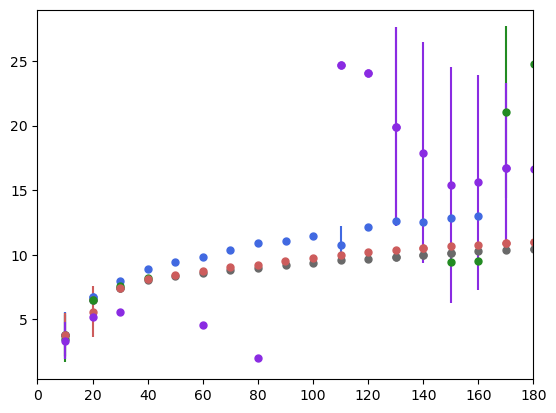

In [16]:
for isim, sim_name in enumerate(sim_names):
    plt.errorbar(all_standoff_radii[isim]["times"], all_standoff_radii[isim]["standoff_radii"][:,0], yerr=all_standoff_radii[isim]["standoff_radii"][:,1], label=sim_name, color=bowshock_config[sim_name]["color"], marker='o', markersize=5, ls="")
plt.xlim(0, 180)